In [6]:
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt

In [7]:
# Shared data, selection rules, and plotting style for all three panels.
# Run with reproduction as the working directory.
RESULT_DIR = Path("figure15/data")
LANES, BLOCKS = range(1, 8), range(1, 7)
NB_F1 = [0.6357, 0.6648, 0.6761, 0.7068, 0.7068, 0.7068, 0.7068]
MODEL_FILES = {
    "DT": ("dt_ciciot22_lane_cost_100.txt", "#1F77B4"),
    "RF": ("rf_ciciot22_lane_cost_100_allcases.txt", "#FF7F0E"),
}
DEPLOYMENTS = {
    "SRAM": ("SS", ["SS Entries"], "o", "-"),
    "TCAM": ("SS RANGE", ["SS RANGE SRAM", "SS RANGE TCAM"], "^", "--"),
}
MODELS = [
    dict(label=f"{model}_sram {memory}", model=model, color=color,
         prefix=prefix, columns=columns, marker=marker, linestyle=linestyle)
    for model, (_, color) in MODEL_FILES.items()
    for memory, (prefix, columns, marker, linestyle) in DEPLOYMENTS.items()
]


def read_table(path):
    lines = [line.strip() for line in path.read_text(encoding="utf-8").splitlines()
             if line.strip()]
    if len(lines) < 3:
        raise ValueError(f"{path} does not contain a complete result table")
    headers = re.split(r"\s{2,}", lines[0])
    rows = []
    for line in lines[2:]:
        values = re.split(r"\s{2,}", line)
        if len(values) != len(headers):
            raise ValueError(f"{path} has {len(values)} values for {len(headers)} columns")
        rows.append(dict(zip(headers, values)))
    return rows


TABLES = {model: read_table(RESULT_DIR / filename)
          for model, (filename, _) in MODEL_FILES.items()}


def select_best(group, counts):
    """Maximize F1; break ties by the other resource count, then memory cost."""
    tie_column = "# ML blocks" if group == "lanes" else "# lanes"
    series = {}
    for model in MODELS:
        best = {}
        for row in TABLES[model["model"]]:
            count = int(row[f"# {group}"])
            costs = [row[column].strip() for column in model["columns"]]
            if count not in counts or not all(cost.isdigit() for cost in costs):
                continue
            key = (float(row["macro-f1"]), -int(row[tie_column]), -sum(map(int, costs)))
            if count not in best or key > best[count][0]:
                best[count] = (key, row)
        series[model["label"]] = {count: row for count, (_, row) in best.items()}
    return series


def macro_f1(row, prefix):
    return float(row["macro-f1"])


def duplication_ratio(row, prefix):
    used_slots = 0
    for lane in range(7):
        text = row[f"{prefix} lane_{lane}"].strip()
        if not text.startswith("[") or not text.endswith("]"):
            raise ValueError(f"unexpected lane assignment: {text!r}")
        used_slots += sum(value.strip() != "N" for value in text[1:-1].split(","))
    return used_slots / int(row["# feature"])


plt.rcParams.update({
    "font.family": "Times New Roman", "font.serif": ["Times New Roman"],
    "font.size": 22, "pdf.fonttype": 42, "ps.fonttype": 42,
})


def plot_series(series, counts, baseline, xlabel, ylabel, *, metric=macro_f1,
                figsize=(6, 4), ylim=None, padding=0.01, cap=1.0,
                legend=False, nb_label="DS2 NB"):
    fig, ax = plt.subplots(figsize=figsize)
    values = list(baseline)
    for model in MODELS:
        points = series[model["label"]]
        y = [metric(points[count], model["prefix"]) if count in points else math.nan
             for count in counts]
        values.extend(value for value in y if not math.isnan(value))
        ax.plot(list(counts), y, label=model["label"], color=model["color"],
                marker=model["marker"], linestyle=model["linestyle"],
                linewidth=2.0, markersize=7)
    ax.plot(list(counts), baseline, label=nb_label, color="#2CA02C",
            marker="o", linestyle="-", linewidth=2.0, markersize=7)
    margin = max(padding, (max(values) - min(values)) * 0.15)
    ax.set(xlabel=xlabel, ylabel=ylabel, xticks=list(counts),
           xlim=(min(counts) - 0.2, max(counts) + 0.2),
           ylim=ylim or (max(0.0, min(values) - margin), min(cap, max(values) + margin)))
    ax.grid(True, axis="y", alpha=0.3)
    ax.grid(True, axis="x", alpha=0.12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if legend:
        ax.legend(frameon=False, fontsize=14, ncol=3, loc="lower left",
                  bbox_to_anchor=(0.1, -0.05), columnspacing=0.8)
    fig.tight_layout()
    plt.show()

# Figure 15(a)

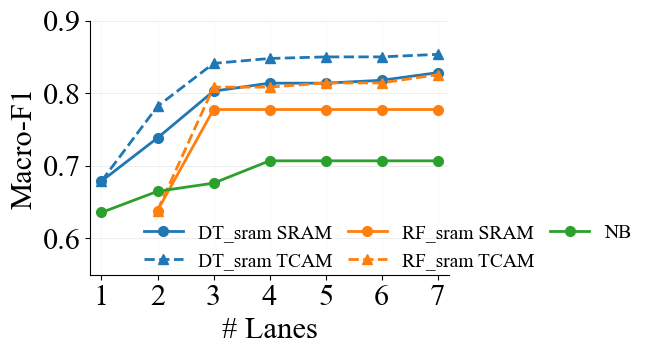

In [8]:
lane_series = select_best("lanes", LANES)
plot_series(lane_series, LANES, NB_F1, "# Lanes", "Macro-F1",
            ylim=(0.55, 0.9), legend=True, nb_label="NB")

# Figure 15(b)

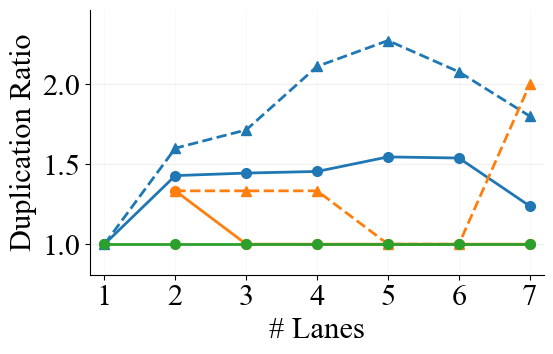

In [9]:
# Reuse the best-F1 configurations selected for Figure 15(a).
feature_series = lane_series
plot_series(feature_series, LANES, [1.0] * len(LANES), "# Lanes", "Duplication Ratio",
            metric=duplication_ratio, padding=0.05, cap=math.inf)

# Figure 15(c)

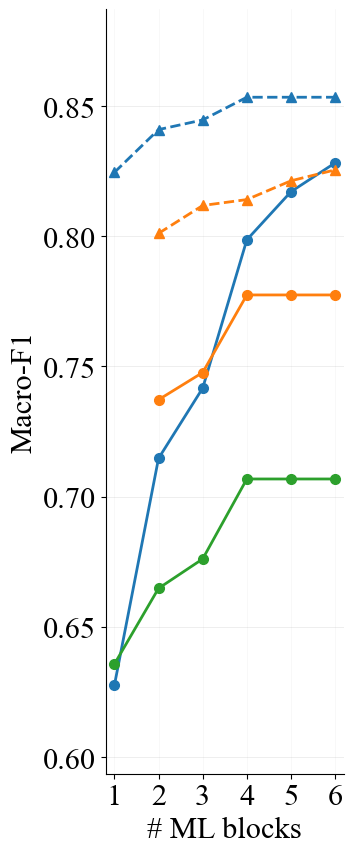

In [10]:
block_series = select_best("ML blocks", BLOCKS)
plot_series(block_series, BLOCKS, NB_F1[:len(BLOCKS)], "# ML blocks", "Macro-F1",
            figsize=(4, 9))